In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

c:\Users\Dhruv\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Dhruv\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3


In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv(f"{path}/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum())
print(df.duplicated().sum())
print(df["Class"].value_counts())

(284807, 31)
0
1081
Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [5]:
dups = df[df.duplicated(keep=False)]
print(dups["Class"].value_counts())
print(df.duplicated().groupby(df["Class"]).sum())

Class
0    1822
1      32
Name: count, dtype: int64
Class
0    1062
1      19
dtype: int64


In [6]:
df[['Time','Amount', 'Class']].head()

,Time,Amount,Class
0,0.0,149.62,0
1,0.0,2.69,0
2,1.0,378.66,0
3,1.0,123.50,0
4,2.0,69.99,0


In [7]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("Rows before:", before)
print("Rows after: ", len(df))
print(df["Class"].value_counts())

Rows before: 284807
Rows after:  283726
Class
0    283253
1       473
Name: count, dtype: int64


## Amount

In [8]:
print(df.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


In [9]:
genuine_amounts = df[df["Class"] == 0]["Amount"]

print(genuine_amounts.value_counts().head(10))

Amount
1.00     13461
1.98      6044
0.89      4871
9.99      4737
15.00     3280
0.76      2960
10.00     2948
1.29      2892
1.79      2622
0.99      2304
Name: count, dtype: int64


In [10]:
fraud_amounts = df[df["Class"] == 1]["Amount"]

print(fraud_amounts.value_counts().head(10))

Amount
1.00     105
99.99     27
0.00      25
0.76      17
0.77      10
0.01       5
3.79       4
2.00       4
1.10       3
0.68       3
Name: count, dtype: int64


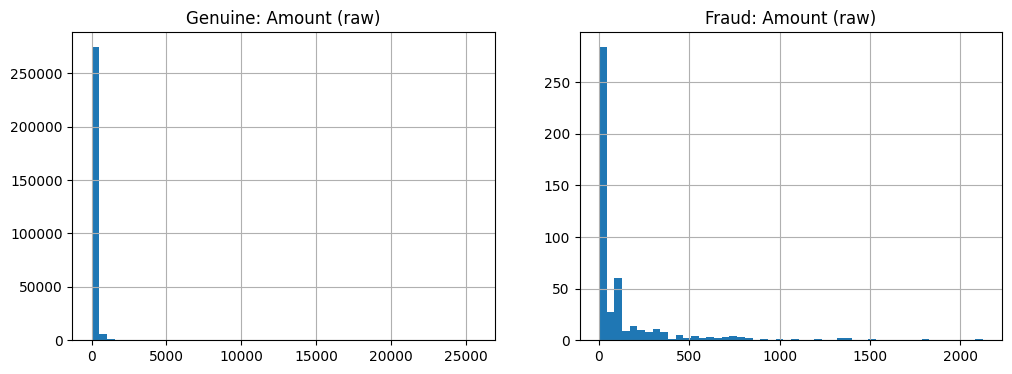

In [11]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[df["Class"] == 0]["Amount"].hist(bins=50, ax=axes[0])
axes[0].set_title("Genuine: Amount (raw)")

df[df["Class"] == 1]["Amount"].hist(bins=50, ax=axes[1])
axes[1].set_title("Fraud: Amount (raw)")

plt.show()

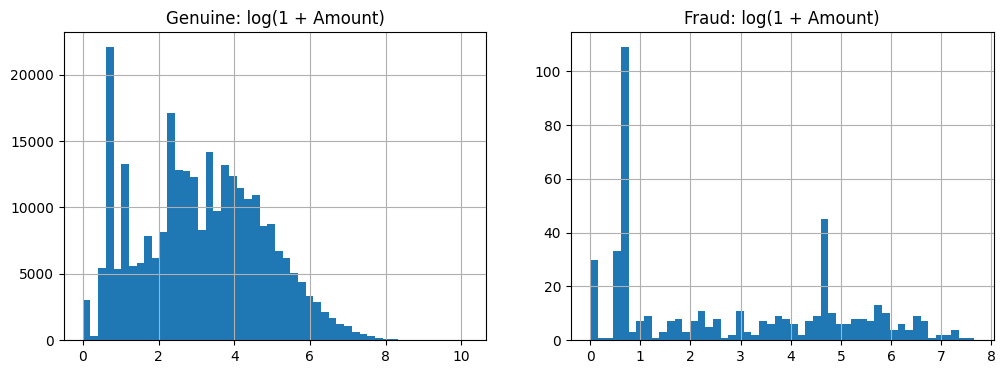

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

np.log1p(df[df["Class"] == 0]["Amount"]).hist(bins=50, ax=axes[0])
axes[0].set_title("Genuine: log(1 + Amount)")

np.log1p(df[df["Class"] == 1]["Amount"]).hist(bins=50, ax=axes[1])
axes[1].set_title("Fraud: log(1 + Amount)")

plt.show()

In [13]:
print("Fraud with Amount <= 1:", (df[df["Class"] == 1]["Amount"] <= 1).mean())
print("Genuine with Amount <= 1:", (df[df["Class"] == 0]["Amount"] <= 1).mean())

Fraud with Amount <= 1: 0.36152219873150104
Genuine with Amount <= 1: 0.1064772482550935


## Time

In [14]:
print(df["Time"].min(), df["Time"].max())
print(df["Time"].is_monotonic_increasing)

0.0 172792.0
True


In [15]:
eda = df.copy()
eda["hour_elapsed"] = (eda["Time"] // 3600).astype(int)   # 0 to 47
eda["hour_of_day"] = eda["hour_elapsed"] % 24
eda["day"] = eda["hour_elapsed"] // 24

In [16]:
hourly = eda.groupby("hour_elapsed")["Class"].agg(total="count", fraud="sum")
hourly["fraud_rate_pct"] = hourly["fraud"] / hourly["total"] * 100
print(hourly)

              total  fraud  fraud_rate_pct
hour_elapsed                              
0              3931      2        0.050878
1              2213      2        0.090375
2              1573     21        1.335029
3              1818     13        0.715072
4              1082      6        0.554529
5              1679     11        0.655152
6              1822      3        0.164654
7              3366     23        0.683304
8              5148      5        0.097125
9              7841     15        0.191302
10             8246      2        0.024254
11             8474     43        0.507435
12             7703      9        0.116838
13             7565      9        0.118969
14             8012     13        0.162257
15             7807     14        0.179326
16             7770     14        0.180180
17             7874     12        0.152400
18             8548     10        0.116986
19             7945      7        0.088106
20             8946      8        0.089425
21         

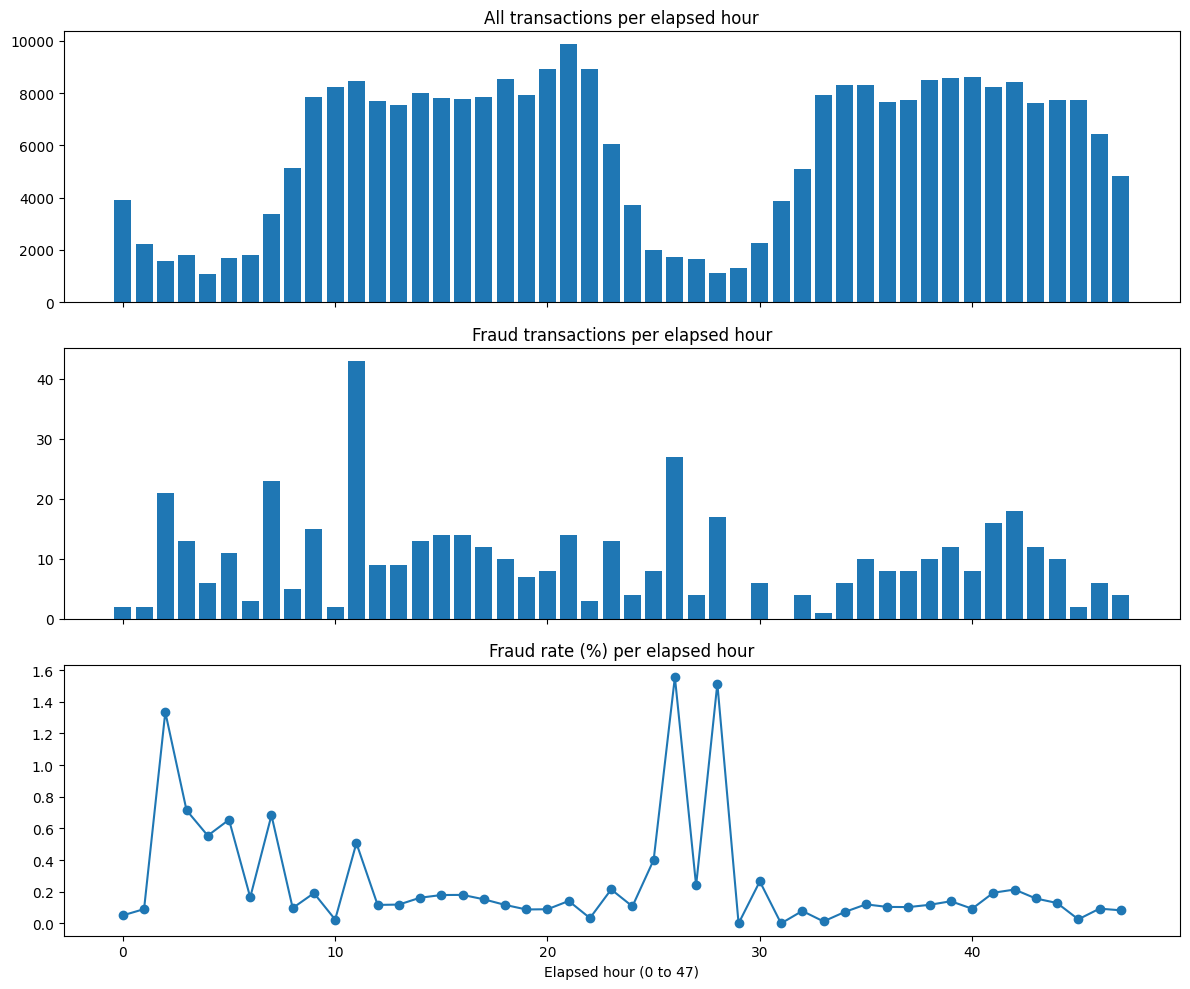

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].bar(hourly.index, hourly["total"])
axes[0].set_title("All transactions per elapsed hour")

axes[1].bar(hourly.index, hourly["fraud"])
axes[1].set_title("Fraud transactions per elapsed hour")

axes[2].plot(hourly.index, hourly["fraud_rate_pct"], marker="o")
axes[2].set_title("Fraud rate (%) per elapsed hour")
axes[2].set_xlabel("Elapsed hour (0 to 47)")

plt.tight_layout()
plt.show()

In [18]:
print(eda.groupby("day")["Class"].agg(total="count", fraud="sum", rate="mean"))

      total  fraud      rate
day                         
0    144236    272  0.001886
1    139490    201  0.001441


## V1 to V28 against Class

In [19]:
v_cols = [f"V{i}" for i in range(1, 29)]
print(df[v_cols].describe().T[["mean", "std", "min", "max"]])

         mean       std         min         max
V1   0.005917  1.948026  -56.407510    2.454930
V2  -0.004135  1.646703  -72.715728   22.057729
V3   0.001613  1.508682  -48.325589    9.382558
V4  -0.002966  1.414184   -5.683171   16.875344
V5   0.001828  1.377008 -113.743307   34.801666
V6  -0.001139  1.331931  -26.160506   73.301626
V7   0.001801  1.227664  -43.557242  120.589494
V8  -0.000854  1.179054  -73.216718   20.007208
V9  -0.001596  1.095492  -13.434066   15.594995
V10 -0.001441  1.076407  -24.588262   23.745136
V11  0.000202  1.018720   -4.797473   12.018913
V12 -0.000715  0.994674  -18.683715    7.848392
V13  0.000603  0.995430   -5.791881    7.126883
V14  0.000252  0.952215  -19.214325   10.526766
V15  0.001043  0.914894   -4.498945    8.877742
V16  0.001162  0.873696  -14.129855   17.315112
V17  0.000170  0.842507  -25.162799    9.253526
V18  0.001515  0.837378   -9.498746    5.041069
V19 -0.000264  0.813379   -7.213527    5.591971
V20  0.000187  0.769984  -54.497720   39

In [20]:
corr = df[v_cols + ["Class"]].corr()["Class"].drop("Class").sort_values()
print(corr)

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V18   -0.105340
V1    -0.094486
V9    -0.094021
V5    -0.087812
V6    -0.043915
V24   -0.007210
V23   -0.006333
V13   -0.003897
V15   -0.003300
V25    0.003202
V26    0.004265
V22    0.004887
V28    0.009682
V20    0.021486
V27    0.021892
V21    0.026357
V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
Name: Class, dtype: float64


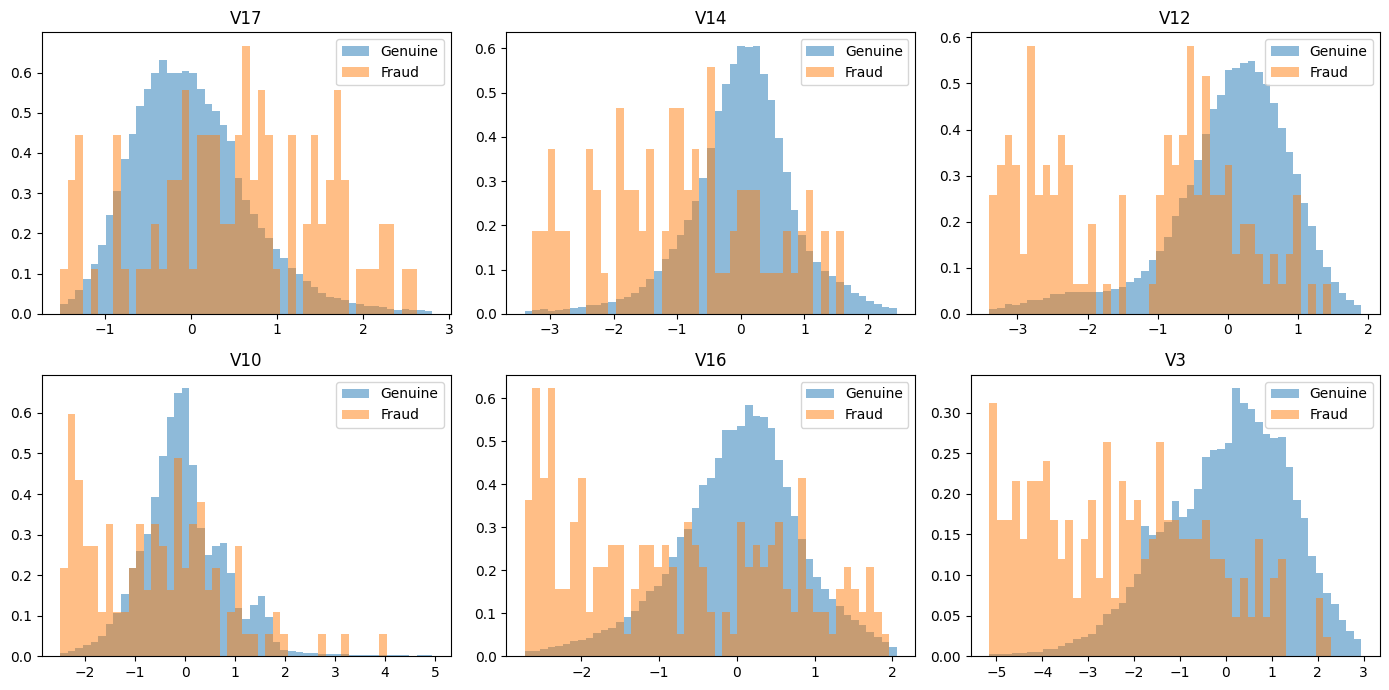

In [21]:
import numpy as np

top = corr.abs().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top):
    lo, hi = df[col].quantile(0.005), df[col].quantile(0.995)
    bins = np.linspace(lo, hi, 50)
    ax.hist(df[df["Class"] == 0][col], bins=bins, density=True, alpha=0.5, label="Genuine")
    ax.hist(df[df["Class"] == 1][col], bins=bins, density=True, alpha=0.5, label="Fraud")
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

## Split-feasibility step

In [22]:
df = df.sort_values("Time").reset_index(drop=True)

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

splits = {
    "train": df.iloc[:train_end],
    "val":   df.iloc[train_end:val_end],
    "test":  df.iloc[val_end:],
}

for name, part in splits.items():
    print(
        f"{name:5s} rows={len(part):7d}  fraud={part['Class'].sum():4d}  "
        f"rate={part['Class'].mean()*100:.3f}%  "
        f"hours={part['Time'].min()/3600:.1f} to {part['Time'].max()/3600:.1f}"
    )

train rows= 198608  fraud= 366  rate=0.184%  hours=0.0 to 36.9
val   rows=  42559  fraud=  55  rate=0.129%  hours=36.9 to 42.0
test  rows=  42559  fraud=  52  rate=0.122%  hours=42.0 to 48.0


In [23]:
from sklearn.model_selection import TimeSeriesSplit

dev = df.iloc[:val_end]          # everything except the test slice
tscv = TimeSeriesSplit(n_splits=5)

for i, (tr_idx, va_idx) in enumerate(tscv.split(dev), start=1):
    tr, va = dev.iloc[tr_idx], dev.iloc[va_idx]
    print(
        f"fold {i}: train rows={len(tr):6d} fraud={tr['Class'].sum():3d} | "
        f"val rows={len(va):6d} fraud={va['Class'].sum():3d}"
    )

fold 1: train rows= 40197 fraud=105 | val rows= 40194 fraud= 91
fold 2: train rows= 80391 fraud=196 | val rows= 40194 fraud= 48
fold 3: train rows=120585 fraud=244 | val rows= 40194 fraud= 94
fold 4: train rows=160779 fraud=338 | val rows= 40194 fraud= 31
fold 5: train rows=200973 fraud=369 | val rows= 40194 fraud= 52


In [24]:
import pandas as pd

qs = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

def tail_table(col):
    genuine = df.loc[df["Class"] == 0, col]
    fraud = df.loc[df["Class"] == 1, col]
    out = pd.DataFrame({
        "genuine": genuine.quantile(qs),
        "fraud": fraud.quantile(qs),
    })
    out.loc["min"] = [genuine.min(), fraud.min()]
    out.loc["max"] = [genuine.max(), fraud.max()]
    return out.round(2)

print(tail_table("V17"))

      genuine  fraud
0.01    -1.32 -22.73
0.05    -0.98 -20.27
0.25    -0.48 -11.59
0.5     -0.07  -5.16
0.75     0.40  -1.13
0.95     1.27   2.88
0.99     2.28   6.30
min    -17.10 -25.16
max      9.25   6.74


In [25]:
top_feats = ["V17", "V14", "V12", "V10", "V16", "V3", "V7", "V11", "V4"]

for col in top_feats:
    print(col)
    print(tail_table(col), "\n")

V17
      genuine  fraud
0.01    -1.32 -22.73
0.05    -0.98 -20.27
0.25    -0.48 -11.59
0.5     -0.07  -5.16
0.75     0.40  -1.13
0.95     1.27   2.88
0.99     2.28   6.30
min    -17.10 -25.16
max      9.25   6.74 

V14
      genuine  fraud
0.01    -2.66 -17.65
0.05    -1.42 -14.16
0.25    -0.42  -9.51
0.5      0.05  -6.59
0.75     0.49  -4.25
0.95     1.39   0.00
0.99     2.15   1.13
min    -18.39 -19.21
max     10.53   3.44 

V12
      genuine  fraud
0.01    -3.00 -17.67
0.05    -1.94 -15.25
0.25    -0.40  -8.60
0.5      0.14  -5.44
0.75     0.62  -2.82
0.95     1.24   0.03
0.99     1.69   0.94
min    -15.14 -18.68
max      7.85   1.38 

V10
      genuine  fraud
0.01    -2.04 -20.15
0.05    -1.33 -14.35
0.25    -0.53  -7.30
0.5     -0.09  -4.47
0.75     0.45  -2.45
0.95     1.55   0.35
0.99     3.19   1.78
min    -14.74 -24.59
max     23.75   4.03 

V16
      genuine  fraud
0.01    -2.33 -12.84
0.05    -1.47 -11.66
0.25    -0.46  -6.47
0.5      0.07  -3.30
0.75     0.52  -1.14
0.95  

In [26]:
rows = []
for col in top_feats:
    g = df.loc[df["Class"] == 0, col]
    f = df.loc[df["Class"] == 1, col]
    rows.append({
        "feature": col,
        "fraud_median": f.median(),
        "genuine_median": g.median(),
        "share_fraud_below_genuine_p01": (f < g.quantile(0.01)).mean(),
        "share_fraud_above_genuine_p99": (f > g.quantile(0.99)).mean(),
    })

summary = pd.DataFrame(rows).set_index("feature").round(3)
print(summary)

         fraud_median  genuine_median  share_fraud_below_genuine_p01  \
feature                                                                
V17            -5.158          -0.065                          0.740   
V14            -6.591           0.051                          0.833   
V12            -5.437           0.141                          0.738   
V10            -4.466          -0.092                          0.795   
V16            -3.303           0.068                          0.645   
V3             -4.875           0.182                          0.607   
V7             -2.902           0.042                          0.507   
V11             3.526          -0.034                          0.000   
V4              4.100          -0.024                          0.000   

         share_fraud_above_genuine_p99  
feature                                 
V17                              0.061  
V14                              0.002  
V12                              0.000  
V1